# 🌌 Sistema de Reconhecimento de EPBs usando 2DPCA

## Equatorial Plasma Bubbles Detection System

### 📋 Pipeline do Sistema:

---

### 🎯 Características do Sistema:

- ✅ **2DPCA** para extração de features preservando estrutura espacial
- ✅ **Ensemble** de 3 classificadores (SVM RBF + SVM Poly + Random Forest)
- ✅ **SMOTE** para balanceamento de classes
- ✅ **Validação cruzada** estratificada
- ✅ **Interpretabilidade** via mapas de importância
- ✅ **Metrics clínicas** (Sensitivity, Specificity, PPV, NPV)

---

**Autor:** Alberto Ivo da Costa Vieira

In [1]:
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix)

from epb_detection_system import load_epb_dataset, augment_epb_data, optimize_n_components, optimize_hyperparameters, plot_comprehensive_analysis, explain_feature_importance, analyze_threshold_sensitivity, plot_calibration_analysis, evaluate_kfold_cv, benchmark_baselines, temporal_train_test_split, explain_shap_importance, setup_logging
from epb_detection_system import EPBRecognitionSystem

setup_logging()

In [2]:
# ========== CONFIGURAÇÕES ==========
DATA_FOLDER = 'data/all-images'         # Pasta com todas as imagens
LABEL_FILE = 'data/epb_labels.csv'      # CSV com labels

TARGET_SIZE = (64, 64)           # Tamanho das imagens
USE_AUGMENTATION = True          # Aplicar data augmentation?
AUGMENT_FACTOR = 3               # Fator de aumento (2x, 3x, etc)
OPTIMIZE_COMPONENTS = True       # Otimizar n_components automaticamente?
MAX_COMPONENTS = 30              # Máximo de componentes a testar
BALANCE_METHOD = 'smote'         # 'smote', 'undersample', ou 'combined'
SPLIT_METHOD = 'random'          # 'random' ou 'temporal' (time-based split por noite)
OPTIMIZE_HYPERPARAMS = True      # Otimização conjunta com RandomizedSearchCV?
N_SEARCH_ITER = 30               # Combinações a testar (mais = mais lento/melhor)

In [3]:
MODEL_VERSION = '1.0'

# Seed global para reprodutibilidade
np.random.seed(42)

print("="*70)
print("🌌 SISTEMA COMPLETO DE RECONHECIMENTO DE EPBs")
print("   Equatorial Plasma Bubbles Detection System")
print("="*70)


# ========== ETAPA 1: CARREGAMENTO E PRÉ-PROCESSAMENTO ==========
print("\n" + "="*70)
print("ETAPA 1: CARREGAMENTO E PRÉ-PROCESSAMENTO")
print("="*70)

X, y, filenames = load_epb_dataset(
    data_folder=DATA_FOLDER,
    label_file=LABEL_FILE,
    target_size=TARGET_SIZE,
    apply_preprocessing=True
)

# Divide em treino e teste
if SPLIT_METHOD == 'temporal':
    print("\n📅 Usando divisão TEMPORAL (time-based split por noite)")
    X_train, X_test, y_train, y_test, files_train, files_test = temporal_train_test_split(
        X, y, filenames, test_size=0.25,
    )
else:
    print("\n🔀 Usando divisão ALEATÓRIA estratificada")
    X_train, X_test, y_train, y_test, files_train, files_test = train_test_split(
        X, y, filenames, test_size=0.25, random_state=42, stratify=y
    )

print(f"\n📦 Divisão {'temporal' if SPLIT_METHOD == 'temporal' else 'estratificada'}:")
print(f"   • Train: {len(X_train)} imagens (EPB: {int(y_train.sum())}, No EPB: {int(len(y_train) - y_train.sum())})")
print(f"   • Test: {len(X_test)} imagens (EPB: {int(y_test.sum())}, No EPB: {int(len(y_test) - y_test.sum())})")

INFO: Carregando dataset de EPBs...
INFO: Labels carregados: 510 registros


🌌 SISTEMA COMPLETO DE RECONHECIMENTO DE EPBs
   Equatorial Plasma Bubbles Detection System

ETAPA 1: CARREGAMENTO E PRÉ-PROCESSAMENTO


INFO: 510 imagens carregadas com sucesso
INFO: Dimensão das imagens: 64x64
INFO: Distribuição das classes:
INFO:   EPBs detectados: 255 (50.0%)
INFO:   No EPB: 255 (50.0%)



🔀 Usando divisão ALEATÓRIA estratificada

📦 Divisão estratificada:
   • Train: 382 imagens (EPB: 191, No EPB: 191)
   • Test: 128 imagens (EPB: 64, No EPB: 64)


In [4]:
# ========== ETAPA 2: OTIMIZAÇÃO DE HIPERPARÂMETROS ==========
# IMPORTANTE: Roda ANTES do augmentation para evitar data leakage.
# O augmentation é feito DENTRO de cada fold da CV, garantindo que
# imagens aumentadas nunca aparecem no fold de validação.
if OPTIMIZE_COMPONENTS:
    print("="*70)
    print("ETAPA 2: OTIMIZAÇÃO DO NÚMERO DE COMPONENTES")
    print("="*70)
    
    best_n_components, optimization_results = optimize_n_components(
        X_train, y_train, 
        max_components=MAX_COMPONENTS,
        cv_folds=5,
        use_augmentation=USE_AUGMENTATION,
        augment_factor=AUGMENT_FACTOR,
    )
else:
    best_n_components = 15  # Value padrão
    print(f"\n⚙️  Usando {best_n_components} componentes (configuração padrão)")

INFO: Otimizando número de componentes (máx=30)...
INFO:   Augmentation dentro dos folds: fator=3
INFO: Aplicando Data Augmentation estratificado (fator base=3)...
INFO:   Classe 0: 153 imgs (fator=x3)
INFO:   Classe 1: 152 imgs (fator=x5)
INFO: Dataset expandido: 305 → 1219 imagens (classe 0: 153→459, classe 1: 152→760)


ETAPA 2: OTIMIZAÇÃO DO NÚMERO DE COMPONENTES


INFO: Aplicando Data Augmentation estratificado (fator base=3)...
INFO:   Classe 0: 152 imgs (fator=x5)
INFO:   Classe 1: 153 imgs (fator=x3)
INFO: Dataset expandido: 305 → 1219 imagens (classe 0: 152→760, classe 1: 153→459)
INFO: Aplicando Data Augmentation estratificado (fator base=3)...
INFO:   Classe 0: 153 imgs (fator=x5)
INFO:   Classe 1: 153 imgs (fator=x3)
INFO: Dataset expandido: 306 → 1224 imagens (classe 0: 153→765, classe 1: 153→459)
INFO: Aplicando Data Augmentation estratificado (fator base=3)...
INFO:   Classe 0: 153 imgs (fator=x5)
INFO:   Classe 1: 153 imgs (fator=x3)
INFO: Dataset expandido: 306 → 1224 imagens (classe 0: 153→765, classe 1: 153→459)
INFO: Aplicando Data Augmentation estratificado (fator base=3)...
INFO:   Classe 0: 153 imgs (fator=x5)
INFO:   Classe 1: 153 imgs (fator=x3)
INFO: Dataset expandido: 306 → 1224 imagens (classe 0: 153→765, classe 1: 153→459)
INFO:    5 comp: F1=1.0000±0.0000 | Var=56.50%
INFO: Aplicando Data Augmentation estratificado (fato

ETAPA 2b: OTIMIZAÇÃO CONJUNTA DE HIPERPARÂMETROS

🔧 OTIMIZAÇÃO CONJUNTA DE HIPERPARÂMETROS
   Combinações a testar: 30
   Folds CV: 5
   Metric: f1
   Amostras: 382

Fitting 5 folds for each of 30 candidates, totalling 150 fits

🏆 MELHORES HIPERPARÂMETROS (f1=1.0000)
   n_components: 5
   svm_C: 10.0
   svm_gamma: auto
   xgb_n_estimators: 100
   xgb_max_depth: 3
   xgb_learning_rate: 0.05
   rf_n_estimators: 300
   rf_max_depth: None
   meta_C: 0.1

📊 Top 5 combinações:
   #1 | Test: 1.0000±0.0000 | Train: 1.0000
       n_components: 5
       xgboost__n_estimators: 100
       xgboost__max_depth: 3
       xgboost__learning_rate: 0.05
       svm_rbf__gamma: auto
       svm_rbf__C: 10.0
       rf__n_estimators: 300
       rf__max_depth: None
       final_estimator__C: 0.1
   #1 | Test: 1.0000±0.0000 | Train: 1.0000
       n_components: 5
       xgboost__n_estimators: 200
       xgboost__max_depth: 3
       xgboost__learning_rate: 0.1
       svm_rbf__gamma: scale
       svm_rbf__C: 10.0
 

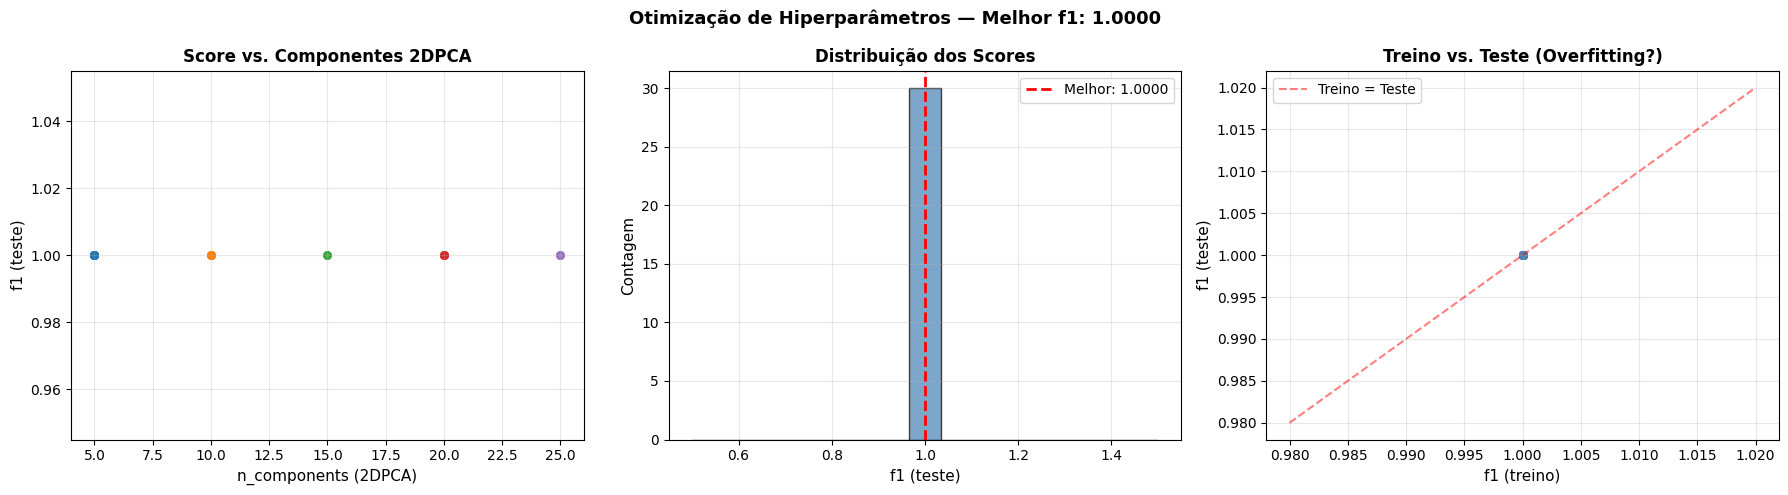


   ✓ n_components atualizado para 5 (da busca conjunta)


In [5]:
# ========== ETAPA 2b: OTIMIZAÇÃO CONJUNTA DE HIPERPARÂMETROS ==========
# Usa RandomizedSearchCV para otimizar simultaneamente:
#   - n_components (2DPCA), C e gamma (SVM), n_estimators/max_depth/lr
#     (XGBoost), n_estimators/max_depth (RF), weights (Voting).
# NOTA: Pode levar 5-30 min dependendo de N_SEARCH_ITER.
# Se desativado, usa os hiperparâmetros padrão (hardcoded).

ensemble_params = None  # Inicializa para Etapa 4

if OPTIMIZE_HYPERPARAMS:
    print("="*70)
    print("ETAPA 2b: OTIMIZAÇÃO CONJUNTA DE HIPERPARÂMETROS")
    print("="*70)
    
    ensemble_params, df_search, fig_search = optimize_hyperparameters(
        X_train, y_train,
        image_shape=TARGET_SIZE,
        n_iter=N_SEARCH_ITER,
        cv_folds=5,
        scoring='f1',
    )
    
    # Sobrepõe n_components da Etapa 2
    best_n_components = ensemble_params['n_components']
    print(f"\n   ✓ n_components atualizado para {best_n_components} (da busca conjunta)")
else:
    print(f"\n⚙️  Otimização conjunta DESATIVADA (OPTIMIZE_HYPERPARAMS = False)")
    print(f"    Usando hiperparâmetros padrão. Ative para busca automática.")

In [6]:
# ========== ETAPA 3: DATA AUGMENTATION ==========
# Aplicado APÓS a otimização de hiperparâmetros para evitar data leakage.
# Apenas expande o conjunto de treino final para a Etapa 4.
if USE_AUGMENTATION and len(X_train) < 2000:
    print("="*70)
    print("ETAPA 3: DATA AUGMENTATION")
    print("="*70)
    
    X_train, y_train = augment_epb_data(X_train, y_train, augment_factor=AUGMENT_FACTOR)

INFO: Aplicando Data Augmentation estratificado (fator base=3)...
INFO:   Classe 0: 191 imgs (fator=x5)
INFO:   Classe 1: 191 imgs (fator=x3)


ETAPA 3: DATA AUGMENTATION


INFO: Dataset expandido: 382 → 1528 imagens (classe 0: 191→955, classe 1: 191→573)


In [7]:
# ========== ETAPA 4: TREINAMENTO DO SISTEMA ==========
print("="*70)
print("ETAPA 4: TREINAMENTO DO SISTEMA COMPLETO")
print("="*70)

system = EPBRecognitionSystem(
    n_components=best_n_components,
    balance_data=True,
    balance_method=BALANCE_METHOD,
    ensemble_params=ensemble_params,
)

system.fit(X_train, y_train)

INFO: Iniciando treinamento do sistema...
INFO: Treinando 2DPCA para extração de features...
INFO: Variância explicada: 56.88%
INFO: Extraindo features...
INFO: Shape das features: (1528, 320)
INFO: Normalizando features...
INFO: Criando classificador ensemble...
INFO: Usando hiperparâmetros otimizados do ensemble:
INFO:   n_components: 5
INFO:   svm_C: 10.0
INFO:   svm_gamma: auto
INFO:   xgb_n_estimators: 100
INFO:   xgb_max_depth: 3
INFO:   xgb_learning_rate: 0.05
INFO:   rf_n_estimators: 300
INFO:   rf_max_depth: None
INFO:   meta_C: 0.1
INFO: Montando pipeline com balanceamento (smote)...
INFO: Classe 0: 955 → 955
INFO: Classe 1: 573 → 955


ETAPA 4: TREINAMENTO DO SISTEMA COMPLETO


INFO: Treinamento concluído!


In [8]:
# ========== ETAPA 5: AVALIAÇÃO NO CONJUNTO DE TESTE ==========
print("="*70)
print("ETAPA 5: AVALIAÇÃO NO CONJUNTO DE TESTE")
print("="*70)

y_pred = system.predict(X_test)
y_proba = system.predict_proba(X_test)

print("\n📊 MÉTRICAS DE PERFORMANCE:")
print("="*70)
print(classification_report(y_test, y_pred, target_names=['No EPB', 'EPB'], digits=4))

# Metrics específicas para EPBs
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
ppv = tp / (tp + fp) if (tp + fp) > 0 else 0
npv = tn / (tn + fn) if (tn + fn) > 0 else 0

print("\n📈 MÉTRICAS CLÍNICAS (IMPORTANTES PARA EPBs):")
print("="*70)
print(f"   • Sensitivity (Recall EPB):  {sensitivity*100:.2f}% ← Detecta EPBs reais")
print(f"   • Specificity:               {specificity*100:.2f}% ← Evita falsos alarmes")
print(f"   • PPV (Precision EPB):       {ppv*100:.2f}% ← Confiança quando detecta")
print(f"   • NPV:                       {npv*100:.2f}% ← Confiança quando não detecta")

print(f"\n   Interpretation:")
if sensitivity > 0.85:
    print(f"   ✓ Excelente detecção de EPBs (perde poucos eventos)")
elif sensitivity > 0.70:
    print(f"   ⚠️  Boa detecção, mas pode perder alguns EPBs")
else:
    print(f"   ❌ Detecção insuficiente - ajuste o modelo")

if specificity > 0.85:
    print(f"   ✓ Poucos falsos alarmes")
else:
    print(f"   ⚠️  Muitos falsos alarmes - ajuste threshold")

ETAPA 5: AVALIAÇÃO NO CONJUNTO DE TESTE

📊 MÉTRICAS DE PERFORMANCE:
              precision    recall  f1-score   support

     No EPB     1.0000    1.0000    1.0000        64
         EPB     1.0000    1.0000    1.0000        64

    accuracy                         1.0000       128
   macro avg     1.0000    1.0000    1.0000       128
weighted avg     1.0000    1.0000    1.0000       128


📈 MÉTRICAS CLÍNICAS (IMPORTANTES PARA EPBs):
   • Sensitivity (Recall EPB):  100.00% ← Detecta EPBs reais
   • Specificity:               100.00% ← Evita falsos alarmes
   • PPV (Precision EPB):       100.00% ← Confiança quando detecta
   • NPV:                       100.00% ← Confiança quando não detecta

   Interpretation:
   ✓ Excelente detecção de EPBs (perde poucos eventos)
   ✓ Poucos falsos alarmes


ETAPA 5b: ANÁLISE DE SENSIBILIDADE AO THRESHOLD


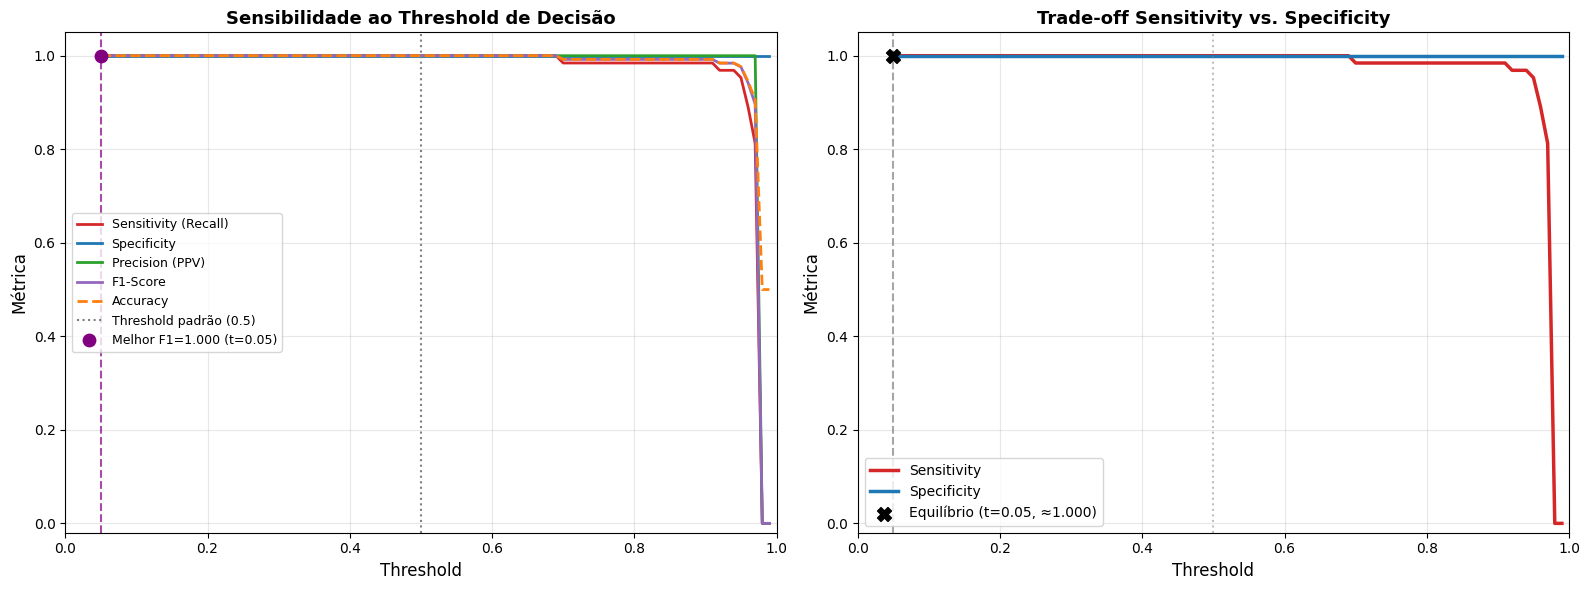


📊 ANÁLISE DE SENSIBILIDADE AO THRESHOLD

   Metric                  t=0.50    Best F1   Equilibrium
   --------------------------------------------------------
   Threshold                  0.50         0.05         0.05
   Sensitivity              1.0000       1.0000       1.0000
   Specificity              1.0000       1.0000       1.0000
   Precision                1.0000       1.0000       1.0000
   F1-Score                 1.0000       1.0000       1.0000
   Accuracy                 1.0000       1.0000       1.0000

   💡 Recomendação:
      O melhor F1 ocorre em t=0.05 (< 0.50) — o threshold padrão
      é conservador. Baixar o threshold aumenta a detecção de EPBs.



In [9]:
# ========== ETAPA 5b: ANÁLISE DE SENSIBILIDADE AO THRESHOLD ==========
print("="*70)
print("ETAPA 5b: ANÁLISE DE SENSIBILIDADE AO THRESHOLD")
print("="*70)

fig_threshold, df_thresholds = analyze_threshold_sensitivity(y_test, y_proba)

ETAPA 5c: ANÁLISE DE CALIBRAÇÃO DE PROBABILIDADES


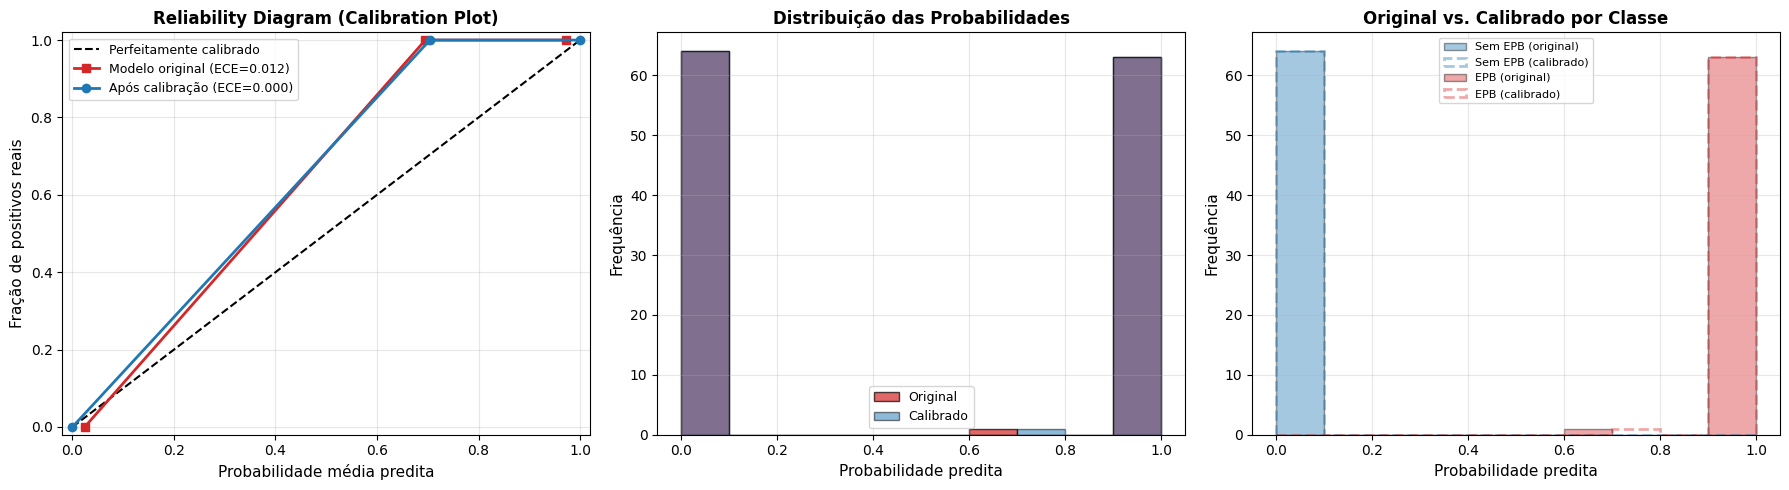


📊 ANÁLISE DE CALIBRAÇÃO DE PROBABILIDADES

   ECE original (Expected Calibration Error): 0.0121
   ✓ Probabilidades bem calibradas
   ECE após calibração isotónica:              0.0000
   ✓ Calibração melhorou o ECE em 0.0121

   💡 Interpretação do reliability diagram:
      Se os pontos ficam ACIMA da diagonal: modelo é subconfiante
        (diz 60%, mas na verdade 80% são positivos)
      Se os pontos ficam ABAIXO da diagonal: modelo é sobreconfiante
        (diz 80%, mas na verdade só 60% são positivos)



In [10]:
# ========== ETAPA 5c: ANÁLISE DE CALIBRAÇÃO DE PROBABILIDADES ==========
print("="*70)
print("ETAPA 5c: ANÁLISE DE CALIBRAÇÃO DE PROBABILIDADES")
print("="*70)

# Prepara features normalizadas para calibração comparativa
X_train_feat = system.scaler.transform(system.extract_features(X_train))
X_test_feat = system.scaler.transform(system.extract_features(X_test))

fig_cal, cal_stats = plot_calibration_analysis(
    y_true=y_test,
    y_proba=y_proba,
    system=system,
    X_train_features=X_train_feat,
    y_train=y_train,
    X_test_features=X_test_feat,
)

INFO: Aplicando Data Augmentation estratificado (fator base=3)...
INFO:   Classe 0: 204 imgs (fator=x5)
INFO:   Classe 1: 204 imgs (fator=x3)



📊 AVALIAÇÃO K-FOLD CROSS-VALIDATION (5 folds)
   Components: 5 | Balanceamento: smote
   Augmentation: Sim (fator=3)
   Total de amostras: 510 (255 EPB, 255 No EPB)



INFO: Dataset expandido: 408 → 1632 imagens (classe 0: 204→1020, classe 1: 204→612)
INFO: Iniciando treinamento do sistema...
INFO: Treinando 2DPCA para extração de features...
INFO: Variância explicada: 56.95%
INFO: Extraindo features...
INFO: Shape das features: (1632, 320)
INFO: Normalizando features...
INFO: Criando classificador ensemble...
INFO: Montando pipeline com balanceamento (smote)...
INFO: Classe 0: 1020 → 1020
INFO: Classe 1: 612 → 1020
INFO: Treinamento concluído!
INFO: Aplicando Data Augmentation estratificado (fator base=3)...
INFO:   Classe 0: 204 imgs (fator=x5)
INFO:   Classe 1: 204 imgs (fator=x3)
INFO: Dataset expandido: 408 → 1632 imagens (classe 0: 204→1020, classe 1: 204→612)
INFO: Iniciando treinamento do sistema...
INFO: Treinando 2DPCA para extração de features...


   Fold 1/5: Acc=1.0000 | Sens=1.0000 | Spec=1.0000 | F1=1.0000 | AUC=1.0000


INFO: Variância explicada: 56.91%
INFO: Extraindo features...
INFO: Shape das features: (1632, 320)
INFO: Normalizando features...
INFO: Criando classificador ensemble...
INFO: Montando pipeline com balanceamento (smote)...
INFO: Classe 0: 1020 → 1020
INFO: Classe 1: 612 → 1020
INFO: Treinamento concluído!
INFO: Aplicando Data Augmentation estratificado (fator base=3)...
INFO:   Classe 0: 204 imgs (fator=x5)
INFO:   Classe 1: 204 imgs (fator=x3)
INFO: Dataset expandido: 408 → 1632 imagens (classe 0: 204→1020, classe 1: 204→612)
INFO: Iniciando treinamento do sistema...
INFO: Treinando 2DPCA para extração de features...


   Fold 2/5: Acc=1.0000 | Sens=1.0000 | Spec=1.0000 | F1=1.0000 | AUC=1.0000


... (2 outputs left out)

INFO: Variância explicada: 56.86%
INFO: Extraindo features...
INFO: Shape das features: (1632, 320)
INFO: Normalizando features...
INFO: Criando classificador ensemble...
INFO: Montando pipeline com balanceamento (smote)...
INFO: Classe 0: 1020 → 1020
INFO: Classe 1: 612 → 1020
INFO: Treinamento concluído!
INFO: Aplicando Data Augmentation estratificado (fator base=3)...
INFO:   Classe 0: 204 imgs (fator=x5)
INFO:   Classe 1: 204 imgs (fator=x3)
INFO: Dataset expandido: 408 → 1632 imagens (classe 0: 204→1020, classe 1: 204→612)
INFO: Iniciando treinamento do sistema...
INFO: Treinando 2DPCA para extração de features...


   Fold 4/5: Acc=1.0000 | Sens=1.0000 | Spec=1.0000 | F1=1.0000 | AUC=1.0000


INFO: Variância explicada: 56.83%
INFO: Extraindo features...
INFO: Shape das features: (1632, 320)
INFO: Normalizando features...
INFO: Criando classificador ensemble...
INFO: Montando pipeline com balanceamento (smote)...
INFO: Classe 0: 1020 → 1020
INFO: Classe 1: 612 → 1020
INFO: Treinamento concluído!
/home/ivo/Documentos/Mestrado/dissertação/code/epb_detection_system.py:2377: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_melt, x='Metric', y='Value', ax=ax, palette='Set2')
/home/ivo/Documentos/Mestrado/dissertação/code/epb_detection_system.py:2382: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([c.capitalize() for c in metrics_cols], rotation=30, ha='right')


   Fold 5/5: Acc=1.0000 | Sens=1.0000 | Spec=1.0000 | F1=1.0000 | AUC=1.0000

📈 RESULTADOS 5-FOLD CROSS-VALIDATION

   Metric                   Média      ± Std        Mín        Máx
   ------------------------------------------------------------
   Accuracy                 1.0000     0.0000     1.0000     1.0000
   Sensitivity              1.0000     0.0000     1.0000     1.0000
   Specificity              1.0000     0.0000     1.0000     1.0000
   Precision                1.0000     0.0000     1.0000     1.0000
   F1                       1.0000     0.0000     1.0000     1.0000
   Auc                      1.0000     0.0000     1.0000     1.0000

   💡 Para reportar na dissertação:
      F1-Score: 1.0000 ± 0.0000
      AUC:      1.0000 ± 0.0000
      Sens.:    1.0000 ± 0.0000


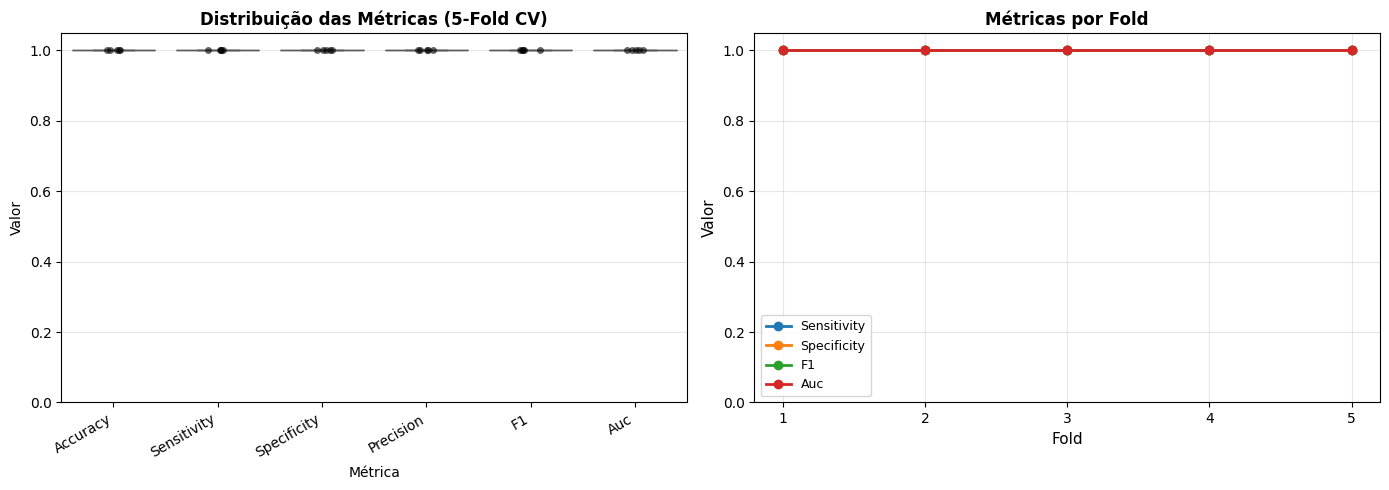

In [11]:
# ========== ETAPA 5d: AVALIAÇÃO K-FOLD CROSS-VALIDATION ==========
# Usa os dados ORIGINAIS (X, y) antes de augmentation/split
# para avaliar o pipeline completo com intervalos de confiança.
# Cada fold treina do zero: augmentation → 2DPCA → SMOTE → ensemble.

fig_kfold, df_kfold = evaluate_kfold_cv(
    X, y,
    n_components=best_n_components,
    n_folds=5,
    balance_method=BALANCE_METHOD,
    use_augmentation=USE_AUGMENTATION,
    augment_factor=AUGMENT_FACTOR,
)


📊 BENCHMARKING CONTRA BASELINES
   Train: 1528 | Test: 128 | Components: 5

   Flatten + LogReg       Acc=1.0000 | Sens=1.0000 | Spec=1.0000 | F1=1.0000 | AUC=1.0000
   PCA + LogReg           Acc=1.0000 | Sens=1.0000 | Spec=1.0000 | F1=1.0000 | AUC=1.0000
   PCA + SVM RBF          Acc=1.0000 | Sens=1.0000 | Spec=1.0000 | F1=1.0000 | AUC=1.0000
   Flatten + RF           Acc=1.0000 | Sens=1.0000 | Spec=1.0000 | F1=1.0000 | AUC=1.0000


INFO: Iniciando treinamento do sistema...
INFO: Treinando 2DPCA para extração de features...
INFO: Variância explicada: 56.88%
INFO: Extraindo features...
INFO: Shape das features: (1528, 320)
INFO: Normalizando features...
INFO: Criando classificador ensemble...
INFO: Montando pipeline com balanceamento (smote)...
INFO: Classe 0: 955 → 955
INFO: Classe 1: 573 → 955


   2DPCA + SVM RBF        Acc=1.0000 | Sens=1.0000 | Spec=1.0000 | F1=1.0000 | AUC=1.0000


INFO: Treinamento concluído!


   2DPCA + Ensemble ★     Acc=1.0000 | Sens=1.0000 | Spec=1.0000 | F1=1.0000 | AUC=1.0000

Modelo                        Acc     Sens     Spec     Prec       F1      AUC
------------------------------------------------------------------------
Flatten + LogReg           1.0000   1.0000   1.0000   1.0000   1.0000   1.0000
PCA + LogReg               1.0000   1.0000   1.0000   1.0000   1.0000   1.0000
PCA + SVM RBF              1.0000   1.0000   1.0000   1.0000   1.0000   1.0000
Flatten + RF               1.0000   1.0000   1.0000   1.0000   1.0000   1.0000
2DPCA + SVM RBF            1.0000   1.0000   1.0000   1.0000   1.0000   1.0000
2DPCA + Ensemble ★         1.0000   1.0000   1.0000   1.0000   1.0000   1.0000

   💡 Vantagem do 2DPCA+Ensemble sobre o melhor baseline:
      ΔF1 = +0.0000 (pior)
      ❌ O baseline é melhor — reveja a arquitetura.


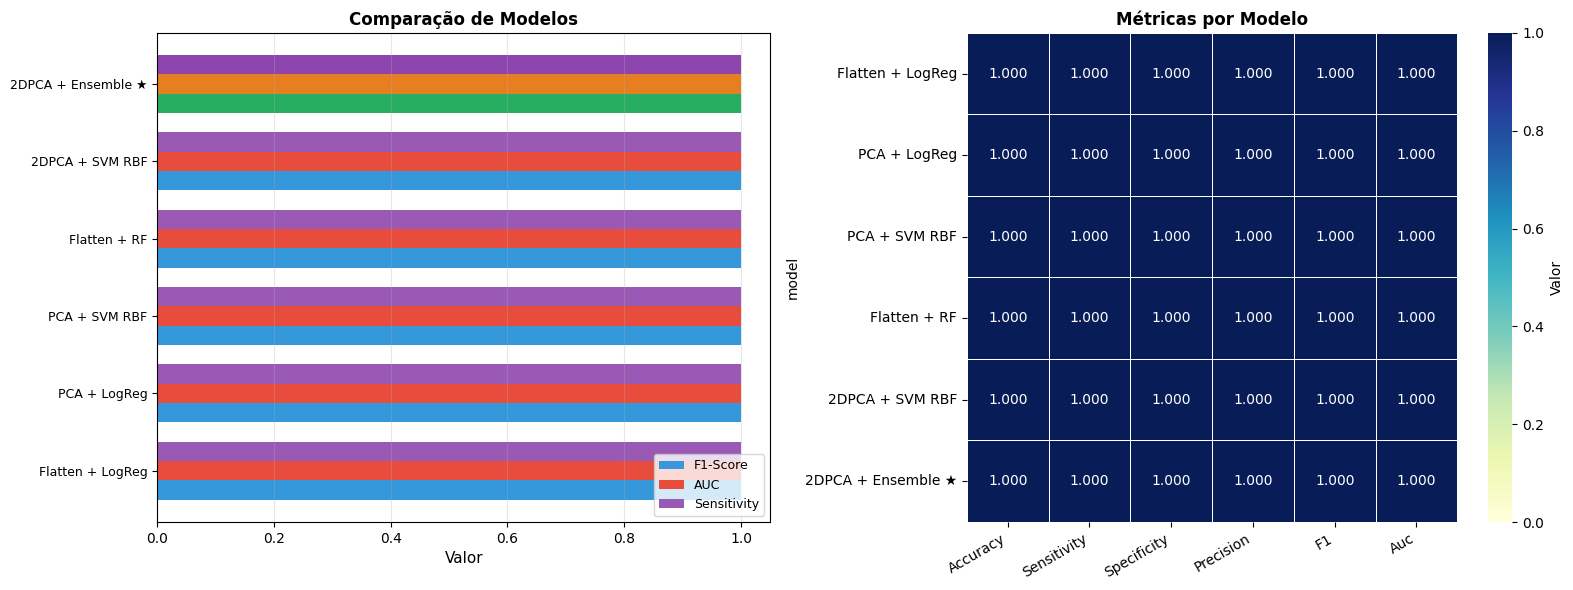

In [12]:
# ========== ETAPA 5e: BENCHMARKING CONTRA BASELINES ==========
# Compara o sistema 2DPCA+Ensemble contra modelos mais simples.
# Justifica a complexidade da arquitetura escolhida.

fig_bench, df_bench = benchmark_baselines(
    X_train, y_train,
    X_test, y_test,
    n_components=best_n_components,
    balance_method=BALANCE_METHOD,
)

ETAPA 6: VISUALIZAÇÃO E ANÁLISE


/home/ivo/miniconda3/envs/mestrado/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 127756 (\N{MILKY WAY}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


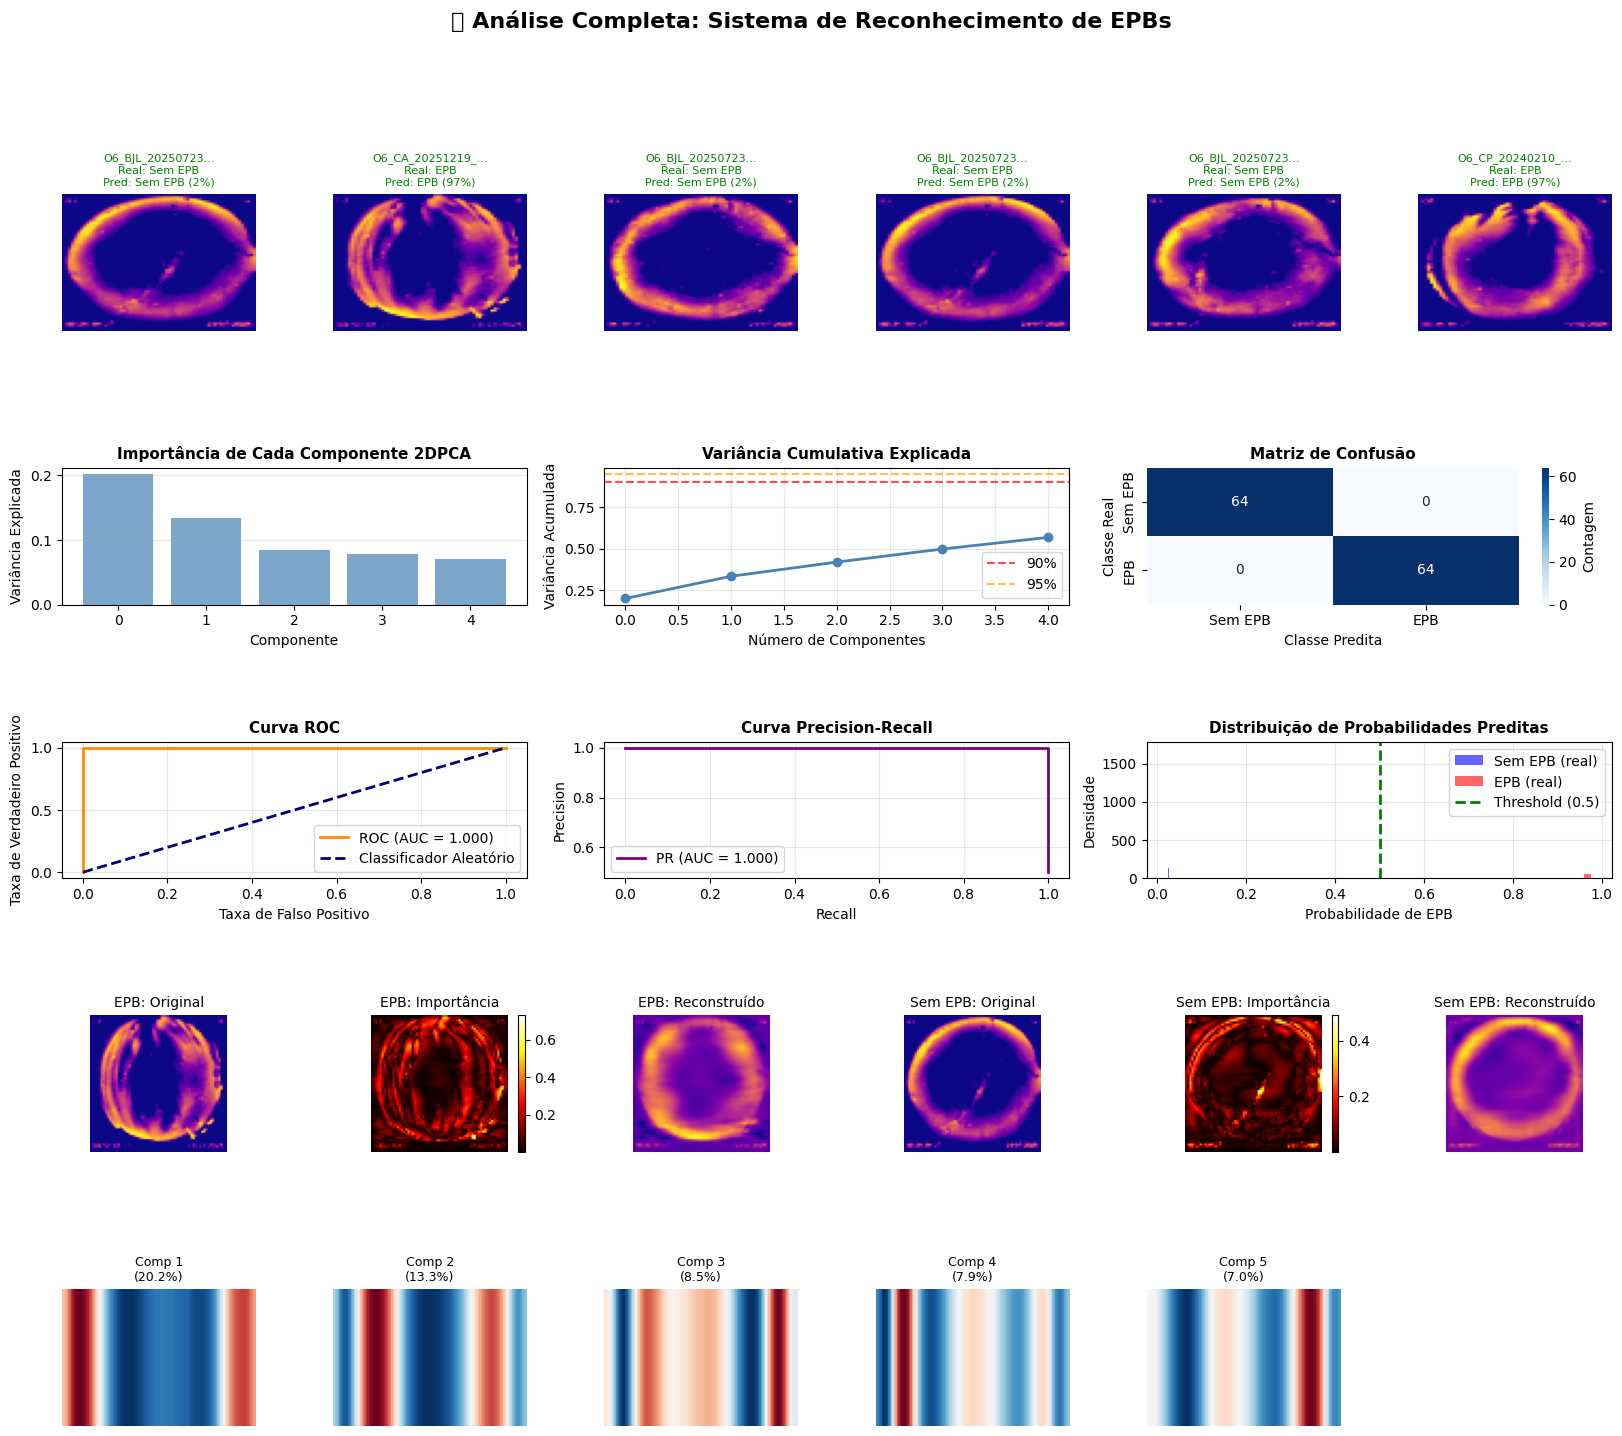

/home/ivo/miniconda3/envs/mestrado/lib/python3.10/site-packages/IPython/core/events.py:82: UserWarning: Glyph 127756 (\N{MILKY WAY}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)


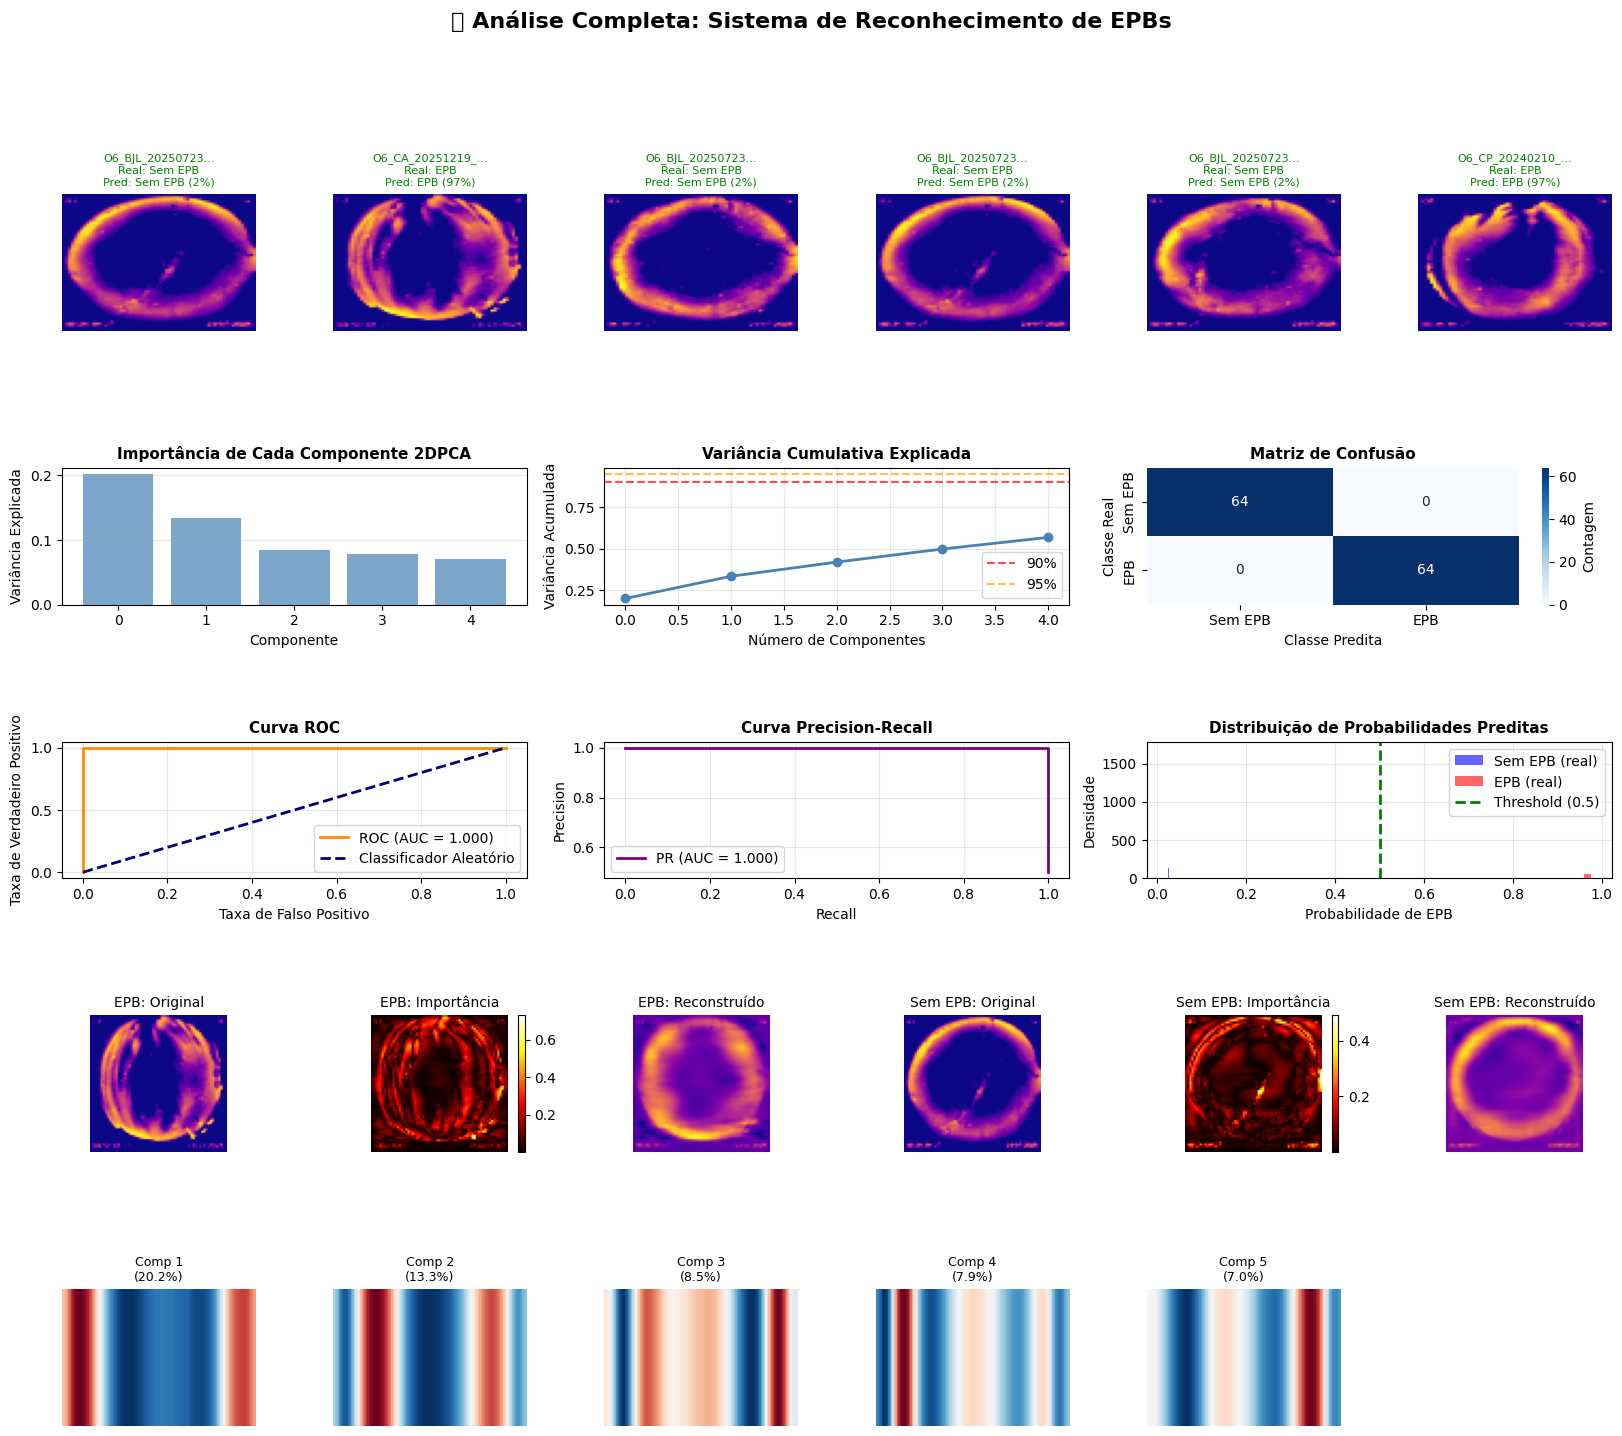

In [13]:
# ========== ETAPA 6: VISUALIZAÇÃO E ANÁLISE ==========
print("="*70)
print("ETAPA 6: VISUALIZAÇÃO E ANÁLISE")
print("="*70)

plot_comprehensive_analysis(system, X_train, X_test, y_train, y_test,
                                y_pred, y_proba, files_test)

ETAPA 7: INTERPRETAÇÃO DE FEATURES (EXEMPLOS)

🔍 FEATURE INTERPRETATION

📸 Imagem: O6_CA_20251219_045046.png
   • True class: EPB
   • Prediction: EPB
   • Probabilidade EPB: 97.24%
   • Confidence: Alta

📊 Most important regions (critical pixels):
   • Upper Left: 147 pixels (35.9%)
   • Upper Right: 104 pixels (25.4%)
   • Lower Right: 103 pixels (25.1%)
   • Lower Left: 56 pixels (13.7%)

💡 Interpretation:
   ✓ The model identified characteristic EPB patterns:
     - Vertical/irregular structures
     - Localized plasma depletions
     - Typical spatial distribution of bubbles


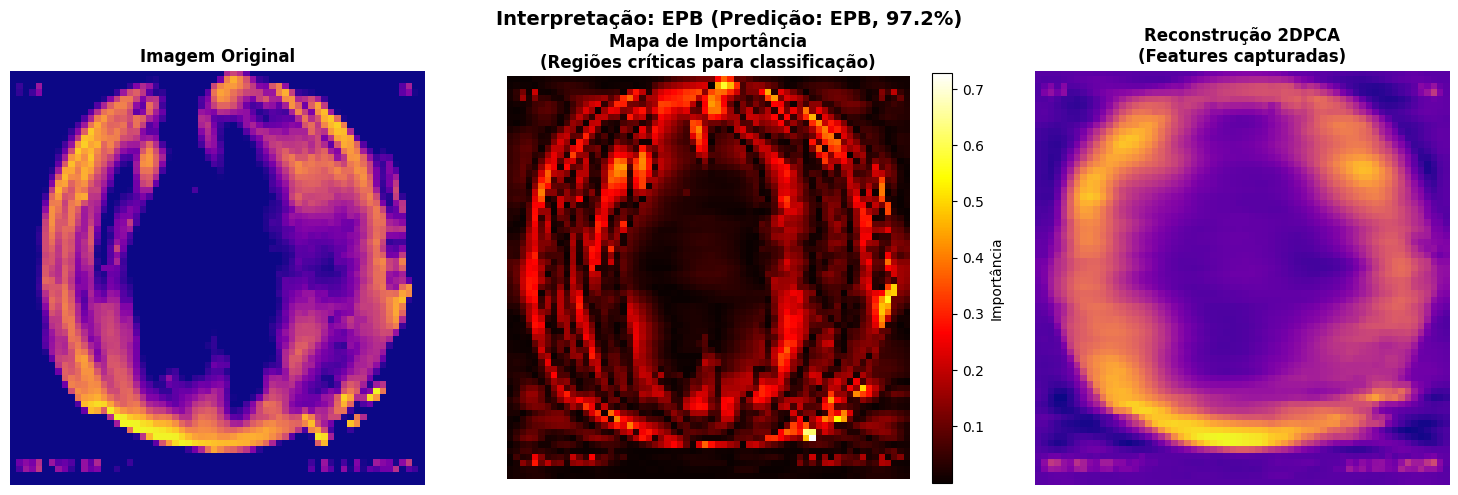

In [14]:
# ========== ETAPA 7: INTERPRETAÇÃO DE FEATURES (EXEMPLOS) ==========
print("="*70)
print("ETAPA 7: INTERPRETAÇÃO DE FEATURES (EXEMPLOS)")
print("="*70)

# Exemplo 1: EPB corretamente classificado
epb_correct_idx = np.where((y_test == 1) & (y_pred == 1))[0]
if len(epb_correct_idx) > 0:
    idx = epb_correct_idx[0]
    explain_feature_importance(system, X_test[idx], y_test[idx], files_test[idx])

# Exemplo 2: Falso positivo (se existir)
fp_idx = np.where((y_test == 0) & (y_pred == 1))[0]
if len(fp_idx) > 0:
    print("\n⚠️  ANÁLISE DE FALSO POSITIVO:")
    idx = fp_idx[0]
    explain_feature_importance(system, X_test[idx], y_test[idx], files_test[idx])

# Exemplo 3: Falso negativo (se existir)
fn_idx = np.where((y_test == 1) & (y_pred == 0))[0]
if len(fn_idx) > 0:
    print("\n⚠️  ANÁLISE DE FALSO NEGATIVO:")
    idx = fn_idx[0]
    explain_feature_importance(system, X_test[idx], y_test[idx], files_test[idx])

ETAPA 7b: ANÁLISE SHAP — IMPORTÂNCIA REAL PARA CLASSIFICAÇÃO


/home/ivo/miniconda3/envs/mestrado/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/ivo/Documentos/Mestrado/dissertação/code/epb_detection_system.py:2744: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/ivo/Documentos/Mestrado/dissertação/code/epb_detection_system.py:2744: UserWarning: Glyph 128309 (\N{LARGE BLUE CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()



🔬 ANÁLISE SHAP — Importance Real para Classificação

📸 Imagem: O6_CA_20251219_045046.png
   • True class: EPB
   • Prediction: EPB (97.2%)
   • Método SHAP: TreeExplainer (tree-based)

📊 SHAP contribution by quadrant:
   • Upper Left: 43.3% (↓ No EPB)
   • Upper Right: 41.2% (↓ No EPB)
   • Lower Left: 7.9% (↓ No EPB)
   • Lower Right: 7.6% (↓ No EPB)

📐 Correlação |SHAP| vs. Reconstruction Error: 0.069 (Spearman)
   → Baixa correlação: SHAP e reconstrução focam em regiões distintas

💡 Interpretation:
   As regiões vermelhas no mapa SHAP mostram onde o modelo
   encontra evidência de EPB (estruturas verticais, deplecções).


/home/ivo/miniconda3/envs/mestrado/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/ivo/miniconda3/envs/mestrado/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128309 (\N{LARGE BLUE CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


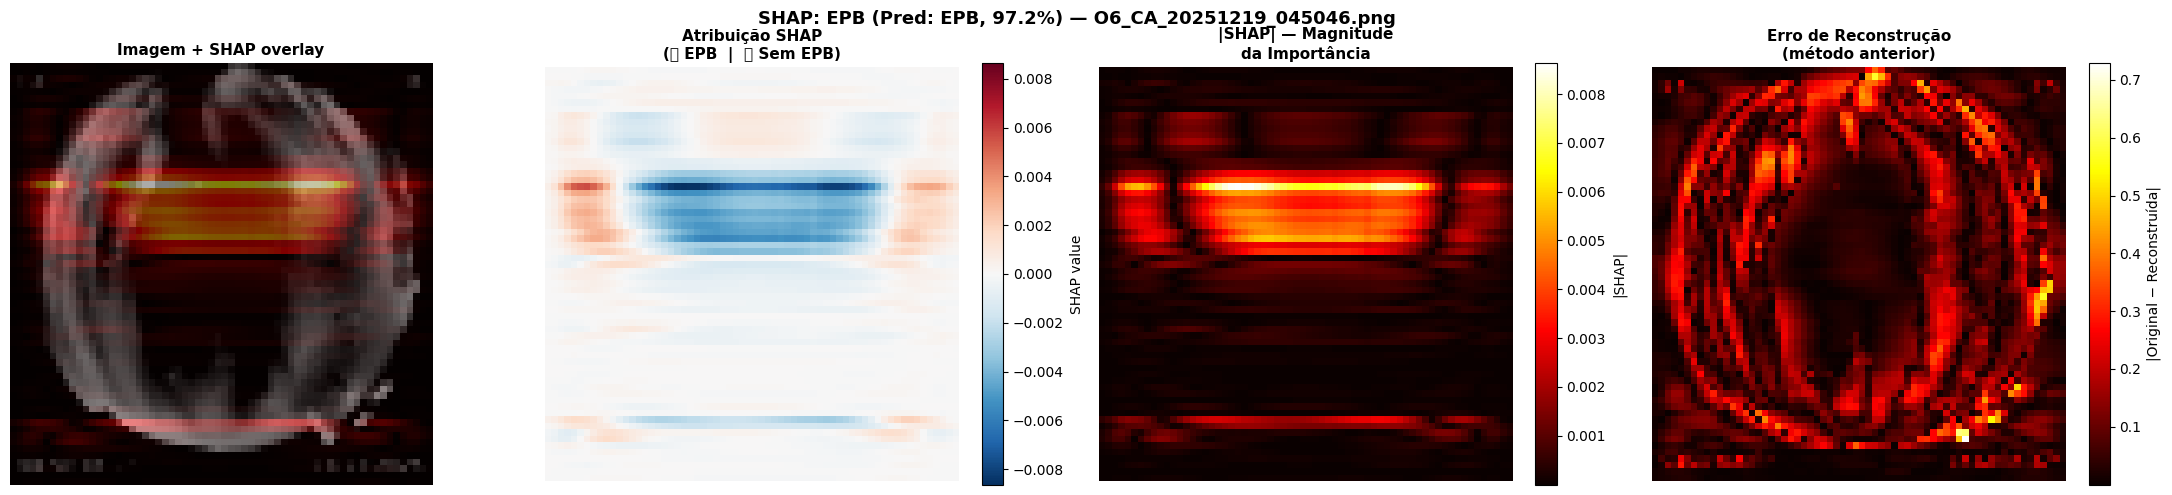

/home/ivo/Documentos/Mestrado/dissertação/code/epb_detection_system.py:2744: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/ivo/Documentos/Mestrado/dissertação/code/epb_detection_system.py:2744: UserWarning: Glyph 128309 (\N{LARGE BLUE CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/ivo/miniconda3/envs/mestrado/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/ivo/miniconda3/envs/mestrado/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128309 (\N{LARGE BLUE CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)



🔬 ANÁLISE SHAP — Importance Real para Classificação

📸 Imagem: O6_BJL_20250723_002439.png
   • True class: No EPB
   • Prediction: No EPB (2.4%)
   • Método SHAP: TreeExplainer (tree-based)

📊 SHAP contribution by quadrant:
   • Upper Left: 46.4% (↑ EPB)
   • Upper Right: 44.3% (↑ EPB)
   • Lower Left: 4.8% (↑ EPB)
   • Lower Right: 4.4% (↑ EPB)

📐 Correlação |SHAP| vs. Reconstruction Error: 0.177 (Spearman)
   → Baixa correlação: SHAP e reconstrução focam em regiões distintas

💡 Interpretation:
   As regiões azuis no mapa SHAP mostram evidência de ionosfera
   quieta (ausência de estruturas irregulares).


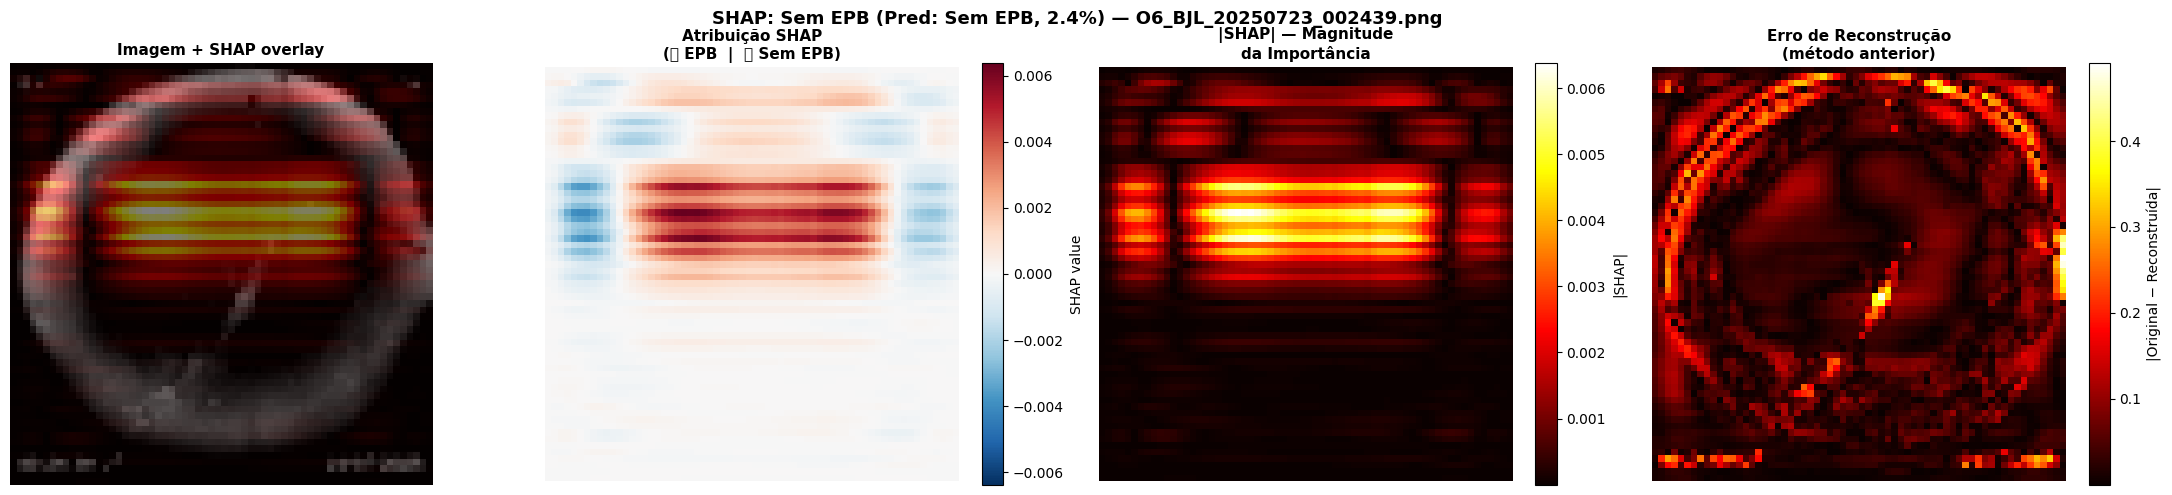

In [15]:
# ========== ETAPA 7b: ANÁLISE SHAP — IMPORTÂNCIA REAL ==========
# O mapa SHAP mostra quais regiões da imagem realmente influenciam
# a decisão do classificador (não apenas o erro de reconstrução 2DPCA).
# Vermelho = evidência a favor de EPB | Azul = evidência contra EPB

print("="*70)
print("ETAPA 7b: ANÁLISE SHAP — IMPORTÂNCIA REAL PARA CLASSIFICAÇÃO")
print("="*70)

# Exemplo 1: EPB corretamente classificado
epb_correct_idx = np.where((y_test == 1) & (y_pred == 1))[0]
if len(epb_correct_idx) > 0:
    idx = epb_correct_idx[0]
    explain_shap_importance(
        system, X_test[idx], y_test[idx], X_train,
        filename=files_test[idx], method='tree',
    )

# Exemplo 2: No EPB corretamente classificado
no_epb_correct_idx = np.where((y_test == 0) & (y_pred == 0))[0]
if len(no_epb_correct_idx) > 0:
    idx = no_epb_correct_idx[0]
    explain_shap_importance(
        system, X_test[idx], y_test[idx], X_train,
        filename=files_test[idx], method='tree',
    )

# Exemplo 3: Erro de classificação (se existir)
errors_idx = np.where(y_test != y_pred)[0]
if len(errors_idx) > 0:
    idx = errors_idx[0]
    print(f"\n⚠️  ANÁLISE SHAP DE ERRO DE CLASSIFICAÇÃO:")
    explain_shap_importance(
        system, X_test[idx], y_test[idx], X_train,
        filename=files_test[idx], method='tree',
    )

In [16]:
# ========== ETAPA 8: SALVAMENTO DO MODELO ==========
from epb_detection_system import EPBModelData, save_model

print("="*70)
print("ETAPA 8: SALVAMENTO DO MODELO")
print("="*70)

model_data = EPBModelData(
    version=MODEL_VERSION,
    system=system,
    n_components=best_n_components,
    target_size=TARGET_SIZE,
    test_metrics={
        'accuracy': float(np.mean(y_pred == y_test)),
        'sensitivity': float(sensitivity),
        'specificity': float(specificity),
        'ppv': float(ppv),
        'npv': float(npv),
    }
)

file_hash = save_model(model_data, 'models/epb_recognition_model.pkl')

print(f"   ✓ Modelo salvo: models/epb_recognition_model.pkl (v{MODEL_VERSION})")
print(f"   ✓ SHA-256: {file_hash[:16]}...")

print("\n" + "="*70)
print("✅ PIPELINE COMPLETO EXECUTADO COM SUCESSO!")
print("="*70)

INFO: Modelo salvo: models/epb_recognition_model.pkl (SHA-256: 301e38ec7ae4269f...)


ETAPA 8: SALVAMENTO DO MODELO
   ✓ Modelo salvo: models/epb_recognition_model.pkl (v1.0)
   ✓ SHA-256: 301e38ec7ae4269f...

✅ PIPELINE COMPLETO EXECUTADO COM SUCESSO!


## 📊 EXPLICAÇÃO DETALHADA DA VISUALIZAÇÃO GERADA

O dashboard de análise é dividido em **5 LINHAS**, cada uma com múltiplos gráficos:

---

### 📍 **LINHA 1: Exemplos de Classificação (6 imagens)**

**O que mostra:** 6 imagens de teste aleatórias com suas predições

**Elementos:**
- **Imagem:** Visualização da imagem EPB processada (colormap plasma)
- **Título verde:** Classificação CORRETA (predição = realidade)
- **Título vermelho:** Classificação INCORRETA (erro do modelo)
- **Informações:** 
  - `Real:` True class (EPB ou No EPB)
  - `Pred:` Classe predita pelo modelo
  - `(X%)` Probabilidade/confiança da predição

**Interpretation:** Permite visualizar rapidamente acertos e erros do modelo em casos reais.

---

### 📍 **LINHA 2: Análise de Features e Performance**

#### **Gráfico 1 (esquerda): Variância por Component 2DPCA**
- **Eixo X:** Índice do componente (0, 1, 2, ...)
- **Eixo Y:** Variância explicada por cada componente
- **Barras azuis:** Quanto cada componente contribui para representar os dados
- **Interpretation:** Primeiros componentes capturam mais informação (barras maiores). Components finais capturam menos (podem ser ruído).

#### **Gráfico 2 (centro-esquerda): Variância Cumulativa**
- **Linha azul:** Soma acumulada da variância explicada
- **Linha vermelha tracejada:** 90% da variância
- **Linha laranja tracejada:** 95% da variância
- **Interpretation:** Mostra quantos componentes são necessários para capturar X% da informação. Ex: "Com 15 componentes, capturamos 92% da variância total".

#### **Gráfico 3 (direita): Confusion Matrix**
- **Linhas:** Classe real (verdade)
- **Colunas:** Classe predita (modelo)
- **Células:**
  - **Upper left (azul escuro):** True Negatives (VN) - No EPB, predito corretamente
  - **Inferior direita (azul escuro):** Verdadeiros Positivos (VP) - EPB, predito corretamente
  - **Superior direita:** Falsos Positivos (FP) - Predisse EPB, mas não tinha
  - **Inferior esquerda:** Falsos Negativos (FN) - Tinha EPB, mas não detectou
- **Interpretation:** Diagonal principal (azul escuro) = acertos. Fora da diagonal = erros.

---

### 📍 **LINHA 3: Metrics de Discriminação**

#### **Gráfico 1 (esquerda): ROC Curve**
- **Linha laranja:** Performance do modelo
- **Linha azul tracejada:** Classificador aleatório (50% de chance)
- **AUC (Area Under Curve):** Área sob a curva (quanto mais próximo de 1.0, melhor)
- **Eixo X:** Taxa de Falsos Positivos (FPR)
- **Eixo Y:** Taxa de Verdadeiros Positivos (TPR/Recall)
- **Interpretation:** 
  - AUC = 1.0: Modelo perfeito
  - AUC = 0.9-0.99: Excelente
  - AUC = 0.8-0.89: Bom
  - AUC = 0.5: Igual a sorte

#### **Gráfico 2 (centro): Precision-Recall Curve**
- **Linha roxa:** Trade-off entre precisão e recall
- **Eixo X:** Recall (sensibilidade - detecta EPBs reais)
- **Eixo Y:** Precision (confiança - evita falsos alarmes)
- **Interpretation:** Quanto mais próximo do canto superior direito, melhor o equilíbrio entre detectar EPBs e evitar falsos alarmes.

#### **Gráfico 3 (direita): Distribuição de Probabilidades**
- **Histograma azul:** Imagens SEM EPB - distribuição das probabilidades preditas
- **Histograma vermelho:** Imagens WITH EPB - distribuição das probabilidades preditas
- **Linha verde vertical:** Threshold de decisão (0.5)
- **Interpretation:** 
  - Boa separação: histogramas bem separados (azul à esquerda, vermelho à direita)
  - Má separação: histogramas sobrepostos (modelo confuso)
  - À esquerda do threshold: predito como "No EPB"
  - À direita do threshold: predito como "EPB"

---

### 📍 **LINHA 4: Interpretação de Features (2 exemplos)**

Para cada classe (EPB e No EPB), mostra 3 imagens:

#### **Sequência 1: Exemplo de EPB**
1. **Original:** Imagem EPB real como foi capturada
2. **Importance Map (hot colormap):**
   - **Vermelho/Amarelo:** Regiões mais importantes para classificação
   - **Azul/Preto:** Regiões menos relevantes
   - Mostra onde o modelo "olha" para decidir
3. **Reconstructed:** Imagem reconstruída pelos componentes 2DPCA
   - Compara com original para ver o que foi preservado/perdido

#### **Sequência 2: Exemplo de No EPB**
- Mesma estrutura acima, mas para uma imagem sem EPB
- Permite comparar quais regiões são importantes em cada classe

**Interpretation:** Valida se o modelo está focando em regiões fisicamente plausíveis para EPBs (estruturas verticais, deplecções de plasma).

---

### 📍 **LINHA 5: Components Principais Visualizados (6 componentes)**

**O que mostra:** Visualização dos primeiros 6 componentes principais do 2DPCA

**Cada subplot:**
- **Imagem:** Representação visual do componente (como um "filtro")
- **Título:** `Comp X (Y%)`
  - `X`: Índice do componente (1, 2, 3, ...)
  - `Y%`: Percentual de variância explicada por esse componente
- **Colormap RdBu_r:** 
  - Vermelho: valores positivos
  - Azul: valores negativos
  - Branco: valores próximos de zero

**Interpretation:** 
- Primeiros componentes (alta % variância): capturam padrões gerais, estrutura principal
- Components posteriores (baixa % variância): capturam detalhes finos, ruído
- Padrões verticais/horizontais: podem indicar características espaciais dos EPBs

---

## 🎯 **COMO INTERPRETAR O SISTEMA COMPLETO**

### ✅ **Sistema BOM:**
- Matriz de confusão: Diagonal forte (muitos VP e VN)
- ROC AUC: > 0.90
- Distribuição de probabilidades: Bem separada
- Mapa de importância: Foca em regiões plausíveis

### ⚠️ **Sistema PRECISA MELHORAR:**
- Matriz de confusão: Muitos FP ou FN
- ROC AUC: < 0.80
- Distribuição de probabilidades: Muito sobreposta
- Mapa de importância: Foca em regiões aleatórias/bordas

### 📌 **Metrics Críticas para EPBs:**
- **Sensitivity (Recall):** Alta → Detecta a maioria dos EPBs reais (evita perder eventos)
- **Specificity:** Alta → Evita falsos alarmes (não confunde ionosfera quieta com EPB)
- **Equilibrium:** Ambos devem ser > 85% para aplicação científica confiável

## 🕐 Análise Temporal de Sequência de Imagens

Esta seção permite analisar como a probabilidade de EPB evolui ao longo de uma noite de observação.

**Funcionalidades:**
- Processa todas as imagens de uma pasta em ordem cronológica
- Gera gráfico de evolução da probabilidade ao longo do tempo
- Identifica transições (mudanças de estado EPB ↔ No EPB)
- Mostra thumbnails das imagens para validação visual
- Gera heatmap temporal para visualização compacta

**Uso científico:**
- Verificar se o modelo detecta EPBs **antes** de serem visíveis
- Identificar precursores de EPBs
- Analisar a dinâmica temporal de eventos ionosféricos